# 02 — Sentetik veri üretimi ve kalite ölçümü

**Sahibi:** Öğrenci 1 · **Rubrik:** Synthetic Data Generation & Fidelity (10 puan)

İki farklı teknik, yalnızca `clean_train` üzerinde:

| Yöntem | Fikir | Ürettiği |
|---|---|---|
| **SMOTE-NC** | Azınlık örneğiyle k komşusu arasında doğrusal enterpolasyon; kategoriklerde komşuların modu | Yalnızca azınlık (default=1) satırları |
| **CTGAN** | Koşullu GAN: generator sahte satır üretir, discriminator gerçekten ayırmaya çalışır | Tüm tablo; koşullu örneklemeyle istenen sınıf |

Adil karşılaştırma için iki yöntem de azınlığa **aynı sayıda** satır ekler (sınıflar 1:1).
CTGAN ayrıca train boyutunda **tam sentetik** bir tablo üretir (TSTR için).

| Çıktı | Kullanan |
|---|---|
| `train_smote.parquet`, `train_ctgan.parquet` | Öğrenci 2 (orijinal/SMOTE/CTGAN karşılaştırması) |
| `synth_ctgan_full.parquet` | TSTR, Öğrenci 3 (Grafik 2-3 final hali) |
| `reports/fidelity*.csv`, `reports/tstr_trtr.csv`, **Grafik 2-3** | Sunum |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from imblearn.over_sampling import SMOTENC
from lightgbm import LGBMClassifier
from sdv.metadata import Metadata
from sdv.sampling import Condition
from sdv.single_table import CTGANSynthesizer
from sdv.utils import load_synthesizer

from src.config import (
    BILL_COLS, CAT_COLS, FEATURES, ID_COL, MODELS_DIR, NUM_COLS, PAY_AMT_COLS, PROCESSED_DIR,
    REPORTS_DIR, SEED, TARGET,
)
from src.data import load_split
from src.plots import INK_MUTED, SEQUENTIAL, SERIES, save_fig, set_style
from src.quality import signed_log1p
from src.synthetic import corr_diff, fidelity_table, summarize_fidelity
from src.utility import lgbm_utility

set_style()
pd.set_option("display.float_format", "{:.4f}".format)
MODELS_DIR.mkdir(exist_ok=True)

In [3]:
train = load_split("train", "clean")
val = load_split("val", "clean")
counts = train[TARGET].value_counts()
N_NEW = int(counts[0] - counts[1])
print("train sınıfları:", counts.to_dict(), f"→ azınlığa eklenecek sentetik satır: {N_NEW:,}")


def with_schema(frame, synthetic):
    """Contract schema: row_id + FEATURES + TARGET + is_synthetic (synthetic row_id = -1)."""
    out = frame[FEATURES + [TARGET]].round().astype("int64").reset_index(drop=True)
    out.insert(0, ID_COL, -1 if synthetic else frame[ID_COL].to_numpy())
    out["is_synthetic"] = synthetic
    return out

train sınıfları: {0: 16334, 1: 4641} → azınlığa eklenecek sentetik satır: 11,693


## 1. SMOTE-NC

Klasik SMOTE kategorik kodlar arasında da enterpolasyon yapar (ör. EDUCATION = 2.4 gibi
anlamsız değerler). **SMOTE-NC** sayısal kolonlarda enterpolasyon, kategorik kolonlarda
komşuların en sık değerini kullanır; komşulukta kategorik farklar sabit bir cezayla
(sayısal std'lerin medyanı) hesaba katılır.

In [4]:
smote = SMOTENC(
    categorical_features=[FEATURES.index(c) for c in CAT_COLS],
    sampling_strategy=1.0,
    k_neighbors=5,
    random_state=SEED,
)
start = time.perf_counter()
X_res, y_res = smote.fit_resample(train[FEATURES], train[TARGET])
print(f"SMOTE-NC: {time.perf_counter() - start:.1f} s")

# imblearn appends the new rows after the original ones.
smote_new = X_res.iloc[len(train):].assign(**{TARGET: y_res.iloc[len(train):].to_numpy()})
train_smote = pd.concat([with_schema(train, False), with_schema(smote_new, True)], ignore_index=True)
train_smote.groupby("is_synthetic")[TARGET].value_counts().unstack()

SMOTE-NC: 1.6 s


default,0,1
is_synthetic,,
False,16334.0000,4641.0000
True,NaN,11693.0000


## 2. CTGAN

CTGAN sayısal kolonları "mode-specific normalization" ile (her kolona bir Gaussian
karışımı uydurup) çok tepeli dağılımları öğrenebilir, kategorik kolonları ise koşullu
vektörle dengeli örnekler. CPU'da eğitim uzun sürdüğü için eğitilen model
`models/ctgan.pkl` olarak önbelleğe alınır (git'e eklenmez); dosya varsa yeniden eğitilmez.

In [5]:
CTGAN_PATH = MODELS_DIR / "ctgan.pkl"
EPOCHS = 300
TABLE = "credit"
real = train[FEATURES + [TARGET]]

metadata = Metadata.detect_from_dataframes({TABLE: real}, infer_keys=None)
for col in CAT_COLS + [TARGET]:
    metadata.update_column(col, table_name=TABLE, sdtype="categorical")
for col in NUM_COLS:
    metadata.update_column(col, table_name=TABLE, sdtype="numerical")

if CTGAN_PATH.exists():
    ctgan = load_synthesizer(str(CTGAN_PATH))
    print("Önbellekten yüklendi:", CTGAN_PATH.name)
else:
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    ctgan = CTGANSynthesizer(metadata, epochs=EPOCHS, enable_gpu=False)
    start = time.perf_counter()
    ctgan.fit({TABLE: real})
    print(f"CTGAN {EPOCHS} epoch: {(time.perf_counter() - start) / 60:.1f} dk")
    ctgan.save(str(CTGAN_PATH))

Önbellekten yüklendi: ctgan.pkl


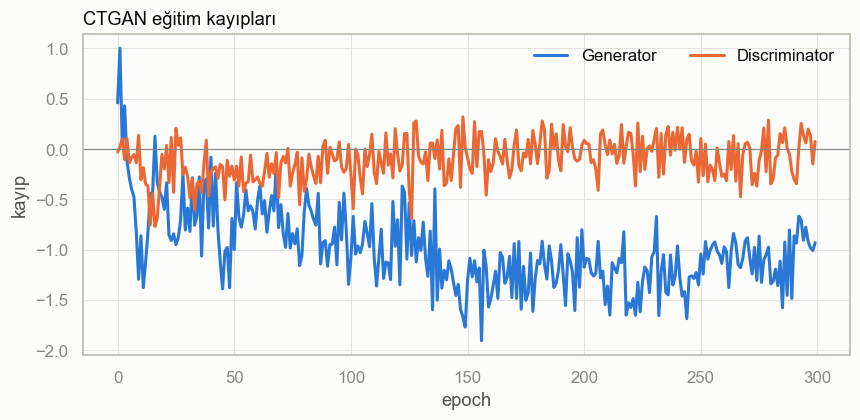

In [6]:
loss = ctgan.get_loss_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(loss["Epoch"], loss["Generator Loss"], color=SERIES[0], label="Generator")
ax.plot(loss["Epoch"], loss["Discriminator Loss"], color=SERIES[1], label="Discriminator")
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.set_xlabel("epoch")
ax.set_ylabel("kayıp")
ax.set_title("CTGAN eğitim kayıpları", loc="left")
ax.legend(ncols=2)
save_fig(fig, "extra_ctgan_loss")
plt.show()

In [7]:
def as_frame(sampled):
    return sampled[TABLE] if isinstance(sampled, dict) else sampled

torch.manual_seed(SEED)
np.random.seed(SEED)
ctgan_full_raw = as_frame(ctgan.sample(num_rows=len(train)))
ctgan_min_raw = as_frame(
    ctgan.sample_from_conditions([Condition(column_values={TARGET: 1}, num_rows=N_NEW)])
)

synth_full = with_schema(ctgan_full_raw, True)
train_ctgan = pd.concat([with_schema(train, False), with_schema(ctgan_min_raw, True)], ignore_index=True)
print("tam sentetik default oranı:", round(synth_full[TARGET].mean(), 4),
      "| gerçek:", round(train[TARGET].mean(), 4))
train_ctgan.groupby("is_synthetic")[TARGET].value_counts().unstack()

  0%|          | 0/11693 [00:00<?, ?it/s]

Sampling conditions:   0%|          | 0/11693 [00:00<?, ?it/s]

Sampling conditions:  25%|██▍       | 2903/11693 [00:00<00:01, 6176.73it/s]

Sampling conditions: 100%|██████████| 11693/11693 [00:01<00:00, 8479.76it/s]

Sampling conditions: 100%|██████████| 11693/11693 [00:01<00:00, 8218.13it/s]

tam sentetik default oranı: 0.2549 | gerçek: 0.2213


default,0,1
is_synthetic,,
False,16334.0000,4641.0000
True,NaN,11693.0000


## 3. İstatistiksel benzerlik (fidelity)

| Karşılaştırma | Gerçek | Sentetik | Neden |
|---|---|---|---|
| SMOTE-NC (azınlık) | train'deki default=1 satırlar | SMOTE'un ürettiği satırlar | SMOTE sadece azınlık üretir |
| CTGAN (azınlık) | train'deki default=1 satırlar | CTGAN'ın koşullu ürettiği satırlar | SMOTE ile birebir kıyas |
| CTGAN (tam veri) | tüm train | tam sentetik tablo | TSTR'de kullanılan veri |

Sayısal kolonlarda **KS istatistiği** (iki dağılımın kümülatif fonksiyonları arasındaki
en büyük fark) ve **Wasserstein mesafesi** (gerçek kolonun std'si birimiyle "bir dağılımı
diğerine taşıma maliyeti"), kategorik kolonlarda **Total Variation Distance** (kategori
oranları farkının yarısı) kullanılır. Hepsinde 0 = birebir aynı.

> Not: ~4.600 ve ~11.700 satırlık örneklerde KS testinin p-değeri çok küçük farkları bile
> "anlamlı" bulur. Bu yüzden p-değerine değil, istatistiğin büyüklüğüne bakıyoruz.

In [8]:
real_min = train[train[TARGET] == 1]
smote_syn = train_smote[train_smote["is_synthetic"]]
ctgan_min = train_ctgan[train_ctgan["is_synthetic"]]

comparisons = {
    "SMOTE-NC (azınlık)": (real_min, smote_syn, False),
    "CTGAN (azınlık)": (real_min, ctgan_min, False),
    "CTGAN (tam veri)": (train, synth_full, True),
}
tables, diffs, summary = {}, {}, {}
for name, (r, s, with_target) in comparisons.items():
    extra = [TARGET] if with_target else []
    tables[name] = fidelity_table(r, s, cat_cols=CAT_COLS + extra)
    diffs[name] = corr_diff(r, s, cols=FEATURES + extra)
    summary[name] = summarize_fidelity(tables[name], diffs[name])

fidelity = pd.concat(tables, names=["comparison"]).reset_index(level=0)
fidelity.to_csv(REPORTS_DIR / "fidelity.csv", index=False)
fidelity_summary = pd.DataFrame(summary).T
fidelity_summary.to_csv(REPORTS_DIR / "fidelity_summary.csv")
fidelity_summary

,mean_ks,mean_wasserstein_std,mean_tvd,mean_abs_corr_diff,max_abs_corr_diff
SMOTE-NC (azınlık),0.0670,0.0358,0.0324,0.0338,0.1241
CTGAN (azınlık),0.1683,0.1226,0.2427,0.0816,0.2792
CTGAN (tam veri),0.1449,0.1047,0.1440,0.0644,0.2366


In [9]:
pivot = fidelity.pivot_table(index="column", columns="comparison",
                             values=["ks_stat", "wasserstein_std", "tvd"])
pivot.dropna(how="all").round(3)

ks_stat                                      \
comparison CTGAN (azınlık) CTGAN (tam veri) SMOTE-NC (azınlık)   
column                                                           
AGE                 0.1040           0.1070             0.0500   
BILL_AMT1           0.1650           0.1600             0.0210   
BILL_AMT2           0.1130           0.0790             0.0240   
BILL_AMT3           0.0900           0.0520             0.0260   
BILL_AMT4           0.0940           0.0660             0.0220   
BILL_AMT5           0.0710           0.1080             0.0330   
BILL_AMT6           0.1490           0.1080             0.0480   
EDUCATION              NaN              NaN                NaN   
LIMIT_BAL           0.1820           0.1610             0.0410   
MARRIAGE               NaN              NaN                NaN   
PAY_0                  NaN              NaN                NaN   
PAY_2                  NaN              NaN                NaN   
PAY_3                  NaN              NaN                NaN   
PAY_4                  NaN              NaN                NaN   
PAY_5                  NaN              NaN                NaN   
PAY_6                  NaN              NaN                NaN   
PAY_AMT1            0.1940           0.1920             0.1030   
PAY_AMT2            0.1630           0.1030             0.0950   
PAY_AMT3            0.3510           0.3270             0.1030   
PAY_AMT4            0.1760           0.1550             0.1130   
PAY_AMT5            0.2920           0.2280             0.1210   
PAY_AMT6            0.2120           0.1830             0.1380   
SEX                    NaN              NaN                NaN   
default                NaN              NaN                NaN   

                       tvd                                      \
comparison CTGAN (azınlık) CTGAN (tam veri) SMOTE-NC (azınlık)   
column                                                           
AGE                    NaN              NaN                NaN   
BILL_AMT1              NaN              NaN                NaN   
BILL_AMT2              NaN              NaN                NaN   
BILL_AMT3              NaN              NaN                NaN   
BILL_AMT4              NaN              NaN                NaN   
BILL_AMT5              NaN              NaN                NaN   
BILL_AMT6              NaN              NaN                NaN   
EDUCATION           0.1650           0.1410             0.0570   
LIMIT_BAL              NaN              NaN                NaN   
MARRIAGE            0.0510           0.0320             0.0130   
PAY_0               0.2320           0.1980             0.0380   
PAY_2               0.2660           0.1900             0.0320   
PAY_3               0.3340           0.2000             0.0370   
PAY_4               0.3490           0.1870             0.0320   
PAY_5               0.3510           0.1790             0.0260   
PAY_6               0.3620           0.1980             0.0360   
PAY_AMT1               NaN              NaN                NaN   
PAY_AMT2               NaN              NaN                NaN   
PAY_AMT3               NaN              NaN                NaN   
PAY_AMT4               NaN              NaN                NaN   
PAY_AMT5               NaN              NaN                NaN   
PAY_AMT6               NaN              NaN                NaN   
SEX                 0.0740           0.0820             0.0200   
default                NaN           0.0340                NaN   

           wasserstein_std                                      
comparison CTGAN (azınlık) CTGAN (tam veri) SMOTE-NC (azınlık)  
column                                                          
AGE                 0.1540           0.1500             0.1080  
BILL_AMT1           0.0870           0.1550             0.0170  
BILL_AMT2           0.0640           0.0830             0.0140  
BILL_AMT3           0.1210           0.0730             0.0110 

**Yorum**

- **SMOTE-NC gerçeğe çok yakın** (ortalama KS 0,067, TVD 0,032, |ΔCorr| 0,034). Bu
  beklenen bir sonuç: her sentetik satır iki gerçek komşunun arasında üretiliyor, yani
  SMOTE yeni bir dağılım öğrenmiyor, mevcut noktaları "dolduruyor". Yüksek benzerliğin
  bedeli düşük çeşitlilik: sentetik satırlar gerçek satırların çok yakın kopyaları.
- **CTGAN belirgin şekilde daha uzak** (azınlıkta ortalama KS 0,168, TVD 0,243). En kötü
  kolonlar ödeme durumu kodları: PAY_3–PAY_6'da TVD 0,33–0,36. CTGAN'ın koşullu vektörü
  nadir kategorileri dengeli örneklemeye çalıştığı için azınlıkta **PAY_0 ≥ 4** oranı
  gerçekte %1,4 iken sentetikte %12,2'ye çıkıyor.
- CTGAN tam veride (tüm sınıflar) daha iyi (TVD 0,144): koşullu örnekleme yalnızca
  azınlığa zorlandığında hata büyüyor.

## 4. Fayda: TSTR ve TRTR

Aynı sabit parametreli LightGBM farklı eğitim setleriyle eğitilir ve **gerçek val**
setinde ölçülür (test seti final modellere ayrılmış durumda, burada kullanılmıyor).

- **TRTR** (Train Real, Test Real): referans.
- **TSTR** (Train Synthetic, Test Real): model hiç gerçek satır görmeden ne kadar öğreniyor?
  Fark ne kadar küçükse sentetik veri o kadar "faydalı".
- **TRA** (Train Real + Augmented): Öğrenci 2'nin kullanacağı artırılmış setler.

In [10]:
scenarios = {
    "TRTR: gerçek train": train,
    "TSTR: CTGAN tam sentetik": synth_full,
    "TRA: gerçek + SMOTE-NC": train_smote,
    "TRA: gerçek + CTGAN": train_ctgan,
}
tstr = pd.DataFrame({name: lgbm_utility(data, val) for name, data in scenarios.items()}).T
tstr.insert(0, "train_rows", [len(d) for d in scenarios.values()])
tstr.insert(1, "train_default_rate", [d[TARGET].mean() for d in scenarios.values()])
tstr.to_csv(REPORTS_DIR / "tstr_trtr.csv")
tstr

,train_rows,train_default_rate,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy
TRTR: gerçek train,20975,0.2213,0.7066,0.7997,0.7771,0.5496,0.8016
TSTR: CTGAN tam sentetik,20975,0.2549,0.6501,0.7611,0.7098,0.4516,0.7633
TRA: gerçek + SMOTE-NC,32668,0.5000,0.6979,0.7988,0.7608,0.5322,0.8062
TRA: gerçek + CTGAN,32668,0.5000,0.6886,0.7839,0.7603,0.5198,0.7824


**Yorum**

- **TSTR açığı:** Yalnızca CTGAN verisiyle eğitilen model, gerçek veriyle eğitilene göre
  Macro-F1'de 0,707 → 0,650 (−0,057), ROC-AUC'de 0,777 → 0,710 (−0,067) kaybediyor. Yani
  CTGAN temerrüt sinyalinin büyük kısmını öğrenmiş ama tamamını değil. Tam sentetik
  tablonun default oranı da biraz yüksek (%25,5, gerçekte %22,1).
- **Artırma (TRA) bu modelde kazanç sağlamıyor:** SMOTE-NC ile 0,698, CTGAN ile 0,689,
  gerçek veriyle 0,707 Macro-F1. Bunun nedeni karar eşiğinin zaten val setinde Macro-F1'e
  göre seçilmesi: dengesizlik eşikle telafi edildiğinde, sınıfları 1:1'e eşitlemek ek
  bilgi getirmiyor, CTGAN'ın gürültüsü ise biraz zarar veriyor.
- Bu sonuç sabit parametreli tek bir LightGBM için geçerli. Ayarlanmış modellerde
  (Perceptron, Optuna-LightGBM, TabNet) üç eğitim setinin karşılaştırmasını Öğrenci 2
  ve 3 yapacak.

## 5. Grafik 2 — Gerçek ve sentetik dağılımlar

Gösterilen 6 özellik, gerçek train'de LightGBM kazanç (gain) önemine göre en önemli 6
özellik. Üç kaynak da **azınlık sınıfından** (default=1), çünkü iki yöntem de bu sınıfı
artırmak için kullanıldı. Kategorik (PAY_x vb.) kolonlarda kod oranları, sayısal
kolonlarda yoğunluk eğrisi; para kolonları işaretli log ölçekte.

En önemli 6 özellik: ['PAY_0', 'BILL_AMT1', 'PAY_AMT2', 'LIMIT_BAL', 'PAY_AMT3', 'PAY_2']


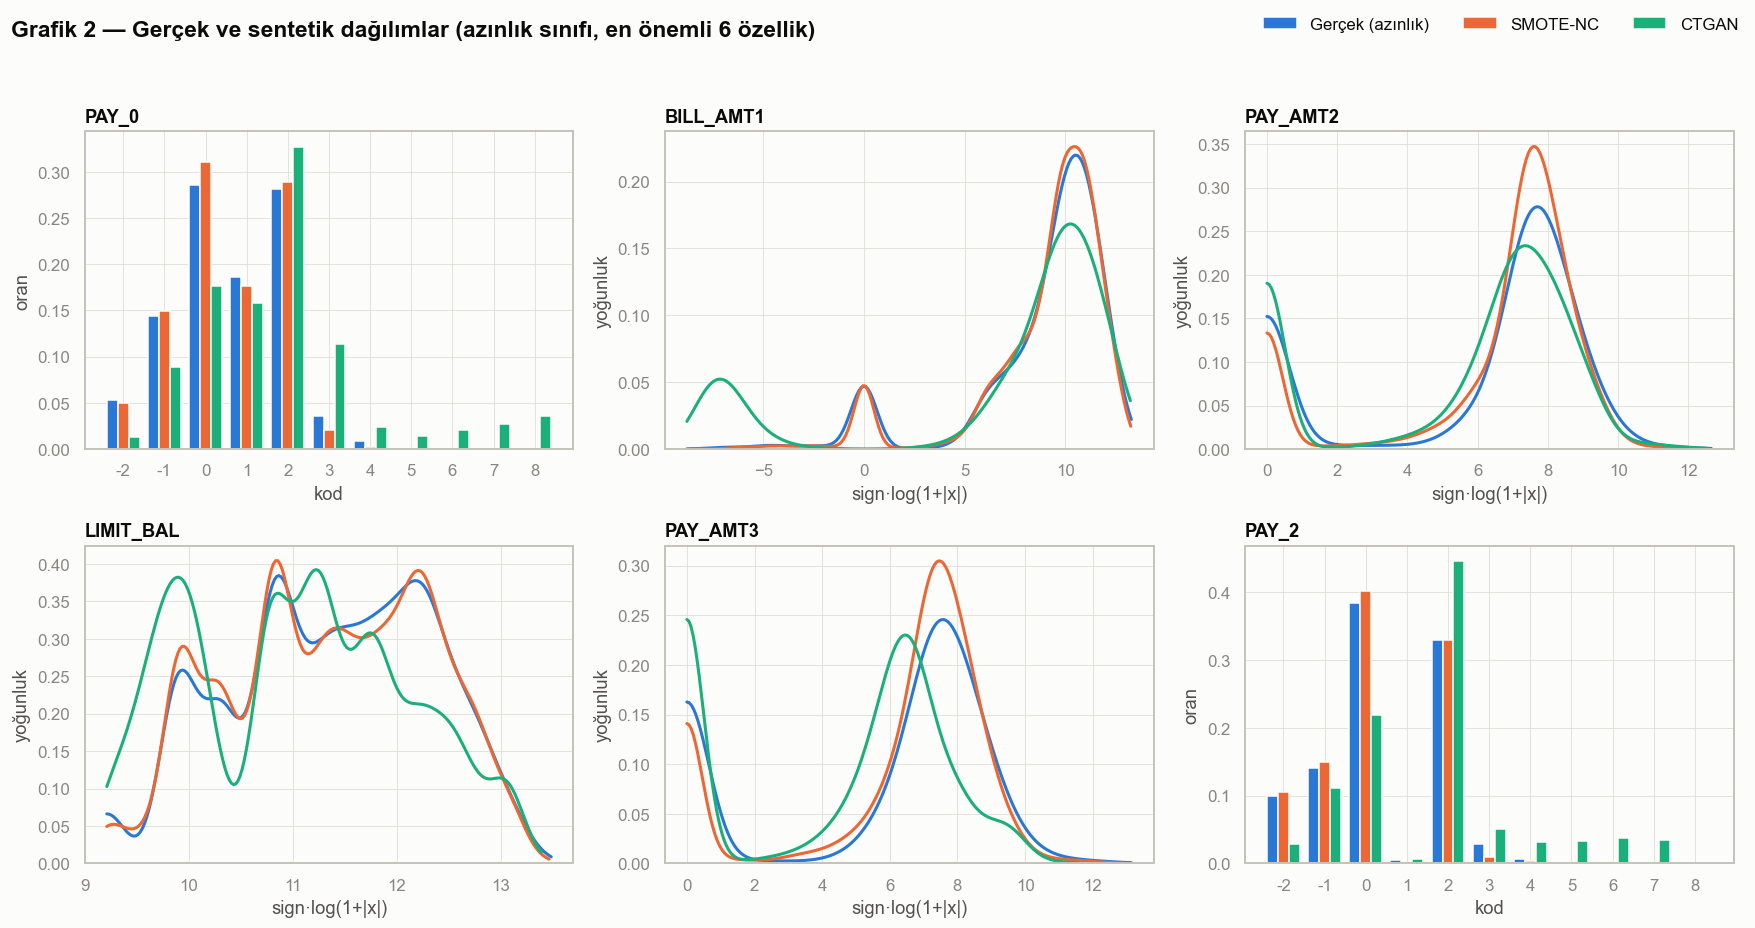

In [11]:
ranker = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1,
                        importance_type="gain").fit(train[FEATURES], train[TARGET])
TOP6 = pd.Series(ranker.feature_importances_, index=FEATURES).nlargest(6).index.tolist()
print("En önemli 6 özellik:", TOP6)

sources = {"Gerçek (azınlık)": real_min, "SMOTE-NC": smote_syn, "CTGAN": ctgan_min}
MONEY = {"LIMIT_BAL", *BILL_COLS, *PAY_AMT_COLS}

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, TOP6):
    if col in CAT_COLS:
        levels = sorted(set().union(*(d[col].unique() for d in sources.values())))
        width = 0.8 / len(sources)
        for i, (name, data) in enumerate(sources.items()):
            share = data[col].value_counts(normalize=True).reindex(levels, fill_value=0)
            ax.bar(np.arange(len(levels)) + (i - 1) * width, share.to_numpy(), width=width,
                   color=SERIES[i], edgecolor="#fcfcfb", linewidth=1, label=name)
        ax.set_xticks(range(len(levels)), levels)
        ax.set_ylabel("oran")
        ax.set_xlabel("kod")
    else:
        for i, (name, data) in enumerate(sources.items()):
            values = signed_log1p(data[col]) if col in MONEY else data[col]
            sns.kdeplot(x=values, ax=ax, color=SERIES[i], label=name, linewidth=2, cut=0)
        ax.set_xlabel("sign·log(1+|x|)" if col in MONEY else col)
        ax.set_ylabel("yoğunluk")
    ax.set_title(col, loc="left", fontweight="bold")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=3, bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Grafik 2 — Gerçek ve sentetik dağılımlar (azınlık sınıfı, en önemli 6 özellik)",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "fig2_real_vs_synth")
plt.show()

**Yorum**

- Turuncu (SMOTE-NC) çizgiler maviyle (gerçek) neredeyse üst üste. Sayısal kolonlarda
  tepeler biraz daha sivri, çünkü enterpolasyon uç değerler yerine aradaki değerleri
  üretiyor.
- Yeşil (CTGAN) çok tepeli yapıyı genel olarak yakalıyor, ama iki belirgin hatası var:
  1. **PAY_0 / PAY_2:** Gerçekte neredeyse hiç görülmeyen 4–8 kodları sentetikte
     %12–14 oranında var.
  2. **BILL_AMT1:** −5 ile −10 (log ölçek) arasında gerçekte olmayan bir tepe var.
     Azınlıkta negatif fatura oranı gerçekte %1,5, CTGAN'da %17,6. Gaussian karışımı,
     nadir negatif modu fazla ağırlıkla öğrenmiş.

## 6. Grafik 3 — Korelasyon farkı matrisi

|Corr_gerçek − Corr_sentetik|: 0'a yakın (açık renk) hücreler, iki özellik arasındaki
ilişkinin sentetik veride korunduğunu gösterir. Üç panel aynı renk ölçeğini kullanır.

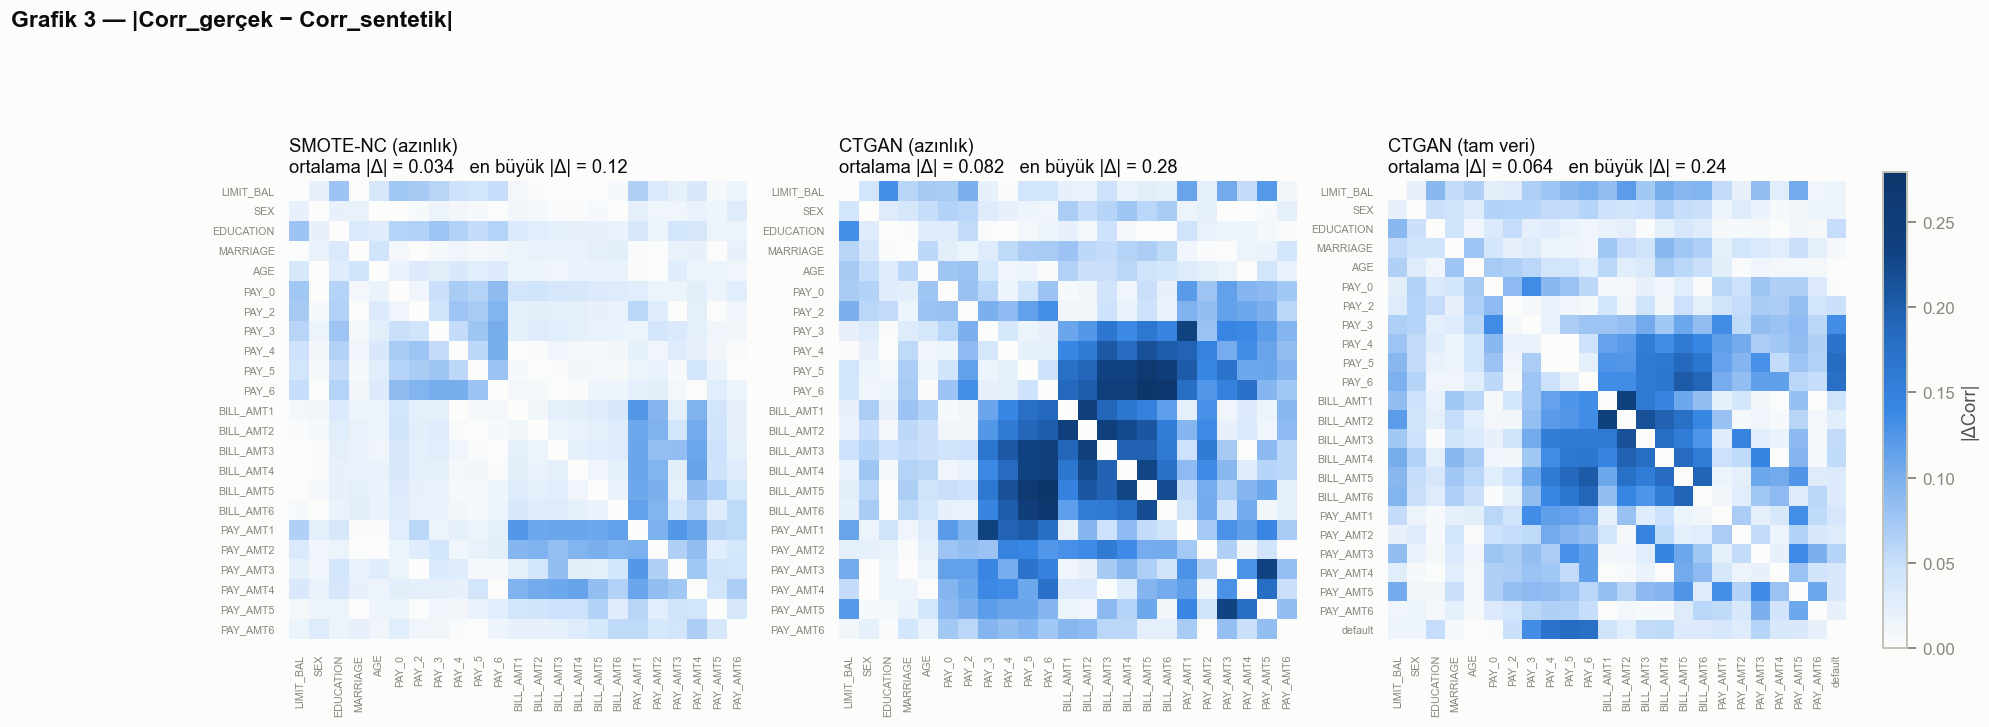

In [12]:
vmax = max(d.to_numpy().max() for d in diffs.values())
fig, axes = plt.subplots(1, 3, figsize=(22, 7.5))
for ax, (name, diff) in zip(axes, diffs.items()):
    sns.heatmap(diff, ax=ax, cmap=SEQUENTIAL, vmin=0, vmax=vmax, square=True, cbar=False,
                xticklabels=True, yticklabels=True, linewidths=0)
    ax.set_title(f"{name}\nortalama |Δ| = {summary[name]['mean_abs_corr_diff']:.3f}   "
                 f"en büyük |Δ| = {summary[name]['max_abs_corr_diff']:.2f}", loc="left")
    ax.tick_params(labelsize=7)
# One shared colorbar so all three panels keep the same size.
fig.colorbar(axes[0].collections[0], ax=axes.tolist(), shrink=0.75, pad=0.02,
             label="|ΔCorr|")
fig.suptitle("Grafik 3 — |Corr_gerçek − Corr_sentetik|", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
save_fig(fig, "fig3_corr_diff")
plt.show()

**Yorum**

- **SMOTE-NC:** Matris neredeyse tamamen açık renkte. Yalnızca PAY_AMT1–4 ile BILL_AMT
  arasında hafif sapma var (|Δ| ≤ 0,12).
- **CTGAN (azınlık):** Koyu blok **PAY_3–6 × BILL_AMT1–6** bölgesinde (|Δ| 0,28'e kadar).
  Gerçek veride ödeme gecikmesi ile fatura tutarları arasındaki ilişki CTGAN'da
  zayıflamış. Bu, Grafik 2'deki PAY kodu hatasıyla tutarlı.
- **CTGAN (tam veri):** Aynı blok daha açık. `default` satırında PAY_3–6 ile hedef
  arasındaki ilişkinin zayıfladığı görülüyor; TSTR açığının bir nedeni bu.

## 7. Sözleşme dosyalarını kaydetme

In [13]:
expected = [ID_COL] + FEATURES + [TARGET, "is_synthetic"]
outputs = {"train_smote": train_smote, "train_ctgan": train_ctgan, "synth_ctgan_full": synth_full}
for name, frame in outputs.items():
    assert list(frame.columns) == expected, name
    assert not frame.isna().any().any(), name
    frame.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)

pd.DataFrame({
    v: load_split("train", v)[TARGET].value_counts().to_dict() for v in ("clean", "smote", "ctgan")
}).T

,0,1
clean,16334,4641
smote,16334,16334
ctgan,16334,16334


## Özet (checkpoint CP-B)

| | SMOTE-NC | CTGAN |
|---|---|---|
| Benzerlik (azınlık, ort. KS / TVD) | **0,067 / 0,032** | 0,168 / 0,243 |
| Korelasyon korunumu (ort. \|ΔCorr\|) | **0,034** | 0,082 |
| Fayda (TRA Macro-F1, val) | **0,698** | 0,689 |
| Yeni bilgi / çeşitlilik | Düşük (gerçek satırların arası) | Yüksek (tüm tabloyu modeller) |
| Maliyet | ~saniyeler | 300 epoch CPU'da onlarca dakika |

- **Benzerlik ve korelasyon korunumunda SMOTE-NC daha iyi.** CTGAN'ın zayıf noktası nadir
  ödeme kodları ve bu kodların fatura tutarlarıyla ilişkisi.
- CTGAN'ın tek başına ürettiği veriyle eğitilen model gerçek veriyle eğitilenin
  ROC-AUC'sinin %91'ine ulaşıyor (0,710 / 0,777).
- **Öğrenci 2 ve 3 için:** `load_split("train", "smote")` ve `load_split("train", "ctgan")`
  hazır. Val ve test setleri değişmedi, `variant="clean"` ile yüklenir.